# Diabetes Risk Prediction – Results for the Research Article


## 1. Setup and load data
Upload `synthetic_diabetes_dataset.xlsx` when asked.

In [1]:
!pip install -q imbalanced-learn shap

import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
RS = 42

FILE = "synthetic_diabetes_dataset.xlsx"
if not os.path.exists(FILE):
    from google.colab import files; files.upload()
df = pd.read_excel(FILE, sheet_name="Patient Data")
print(df.shape, df["Outcome"].value_counts().to_dict())
df.head()

Saving synthetic_diabetes_dataset.xlsx to synthetic_diabetes_dataset.xlsx
(500, 9) {0: 314, 1: 186}


,Patient_ID,Age,Height_cm,Weight_kg,BMI,Blood_Pressure,Insulin,Diabetes_Pedigree_Function,Outcome
0,1,53,178.3,90.0,28.31,67,147,0.310,0
1,2,32,174.1,72.8,24.02,60,102,0.273,0
2,3,59,159.5,67.5,26.53,89,267,0.528,1
3,4,62,152.5,75.4,32.42,81,41,0.473,1
4,5,21,145.0,58.3,27.73,63,63,0.175,0


## 2. Preprocessing and feature engineering
Drop `Patient_ID`, `Height_cm`, `Weight_kg` (BMI already captures them); add `Obese`, `High_BP`, `Age_BMI`.

In [2]:
data = df.copy()
data["Obese"]   = (data["BMI"] >= 30).astype(int)
data["High_BP"] = (data["Blood_Pressure"] >= 80).astype(int)
data["Age_BMI"] = data["Age"] * data["BMI"] / 100
features = ["Age","BMI","Blood_Pressure","Insulin","Diabetes_Pedigree_Function","Obese","High_BP","Age_BMI"]
X, y = data[features], data["Outcome"]
print(X.shape, "| missing:", X.isna().sum().sum(), "| duplicates:", df.duplicated().sum())

(500, 8) | missing: 0 | duplicates: 0


## 3. 5-fold Stratified CV, with and without SMOTE (Tables 3 and 4)
SMOTE sits inside the pipeline, so it is applied to training folds only.

In [3]:
def build(name, smote):
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RS),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RS),
        "Gradient Boosting": GradientBoostingClassifier(random_state=RS),
        "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                 eval_metric="logloss", random_state=RS)}
    steps = []
    if name == "Logistic Regression": steps.append(("scaler", StandardScaler()))
    if smote: steps.append(("smote", SMOTE(random_state=RS)))
    steps.append(("clf", models[name]))
    return ImbPipeline(steps)

K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=RS)
scoring = {"accuracy":"accuracy","precision":"precision","recall":"recall","f1":"f1","roc_auc":"roc_auc"}
NAMES = ["Logistic Regression","Random Forest","Gradient Boosting","XGBoost"]

rows = []
for n in NAMES:
    for sm in [False, True]:
        cv = cross_validate(build(n, sm), X, y, cv=skf, scoring=scoring)
        r = {"Model": n, "SMOTE": "With" if sm else "Without"}
        for m in scoring:
            r[m+"_mean"], r[m+"_std"] = cv["test_"+m].mean(), cv["test_"+m].std()
        rows.append(r)
        print("done:", n, "| SMOTE =", sm)
results = pd.DataFrame(rows)

t3 = results[["Model","SMOTE"]].copy()
for m in scoring:
    t3[m] = results.apply(lambda r: f"{r[m+'_mean']:.3f} ± {r[m+'_std']:.3f}", axis=1)
print("\nTABLE 3 – 5-fold stratified CV (mean ± std)"); display(t3)

piv = results.pivot(index="Model", columns="SMOTE", values=["recall_mean","roc_auc_mean","f1_mean"])
t4 = pd.DataFrame({"Δ Recall": piv["recall_mean"]["With"]-piv["recall_mean"]["Without"],
                   "Δ ROC-AUC": piv["roc_auc_mean"]["With"]-piv["roc_auc_mean"]["Without"],
                   "Δ F1": piv["f1_mean"]["With"]-piv["f1_mean"]["Without"]}).round(3)
print("TABLE 4 – Effect of SMOTE (With − Without)"); display(t4)

done: Logistic Regression | SMOTE = False
done: Logistic Regression | SMOTE = True
done: Random Forest | SMOTE = False
done: Random Forest | SMOTE = True
done: Gradient Boosting | SMOTE = False
done: Gradient Boosting | SMOTE = True
done: XGBoost | SMOTE = False
done: XGBoost | SMOTE = True

TABLE 3 – 5-fold stratified CV (mean ± std)


,Model,SMOTE,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,Without,0.748 ± 0.033,0.709 ± 0.079,0.570 ± 0.034,0.628 ± 0.029,0.802 ± 0.035
1,Logistic Regression,With,0.722 ± 0.044,0.609 ± 0.045,0.705 ± 0.076,0.653 ± 0.056,0.801 ± 0.037
2,Random Forest,Without,0.720 ± 0.041,0.656 ± 0.081,0.532 ± 0.072,0.585 ± 0.066,0.771 ± 0.051
3,Random Forest,With,0.700 ± 0.032,0.593 ± 0.038,0.613 ± 0.082,0.601 ± 0.057,0.766 ± 0.044
4,Gradient Boosting,Without,0.728 ± 0.032,0.666 ± 0.067,0.553 ± 0.043,0.603 ± 0.040,0.782 ± 0.027
5,Gradient Boosting,With,0.712 ± 0.022,0.606 ± 0.030,0.645 ± 0.065,0.624 ± 0.039,0.772 ± 0.021
6,XGBoost,Without,0.722 ± 0.033,0.649 ± 0.054,0.553 ± 0.067,0.596 ± 0.055,0.784 ± 0.037
7,XGBoost,With,0.704 ± 0.021,0.595 ± 0.027,0.650 ± 0.043,0.620 ± 0.024,0.779 ± 0.026


TABLE 4 – Effect of SMOTE (With − Without)


,Δ Recall,Δ ROC-AUC,Δ F1
Model,,,
Gradient Boosting,0.091,-0.010,0.021
Logistic Regression,0.135,-0.001,0.024
Random Forest,0.081,-0.005,0.016
XGBoost,0.097,-0.006,0.025


## 4. Figure 4 and best model
Ranked by ROC-AUC, with recall as tie-breaker.

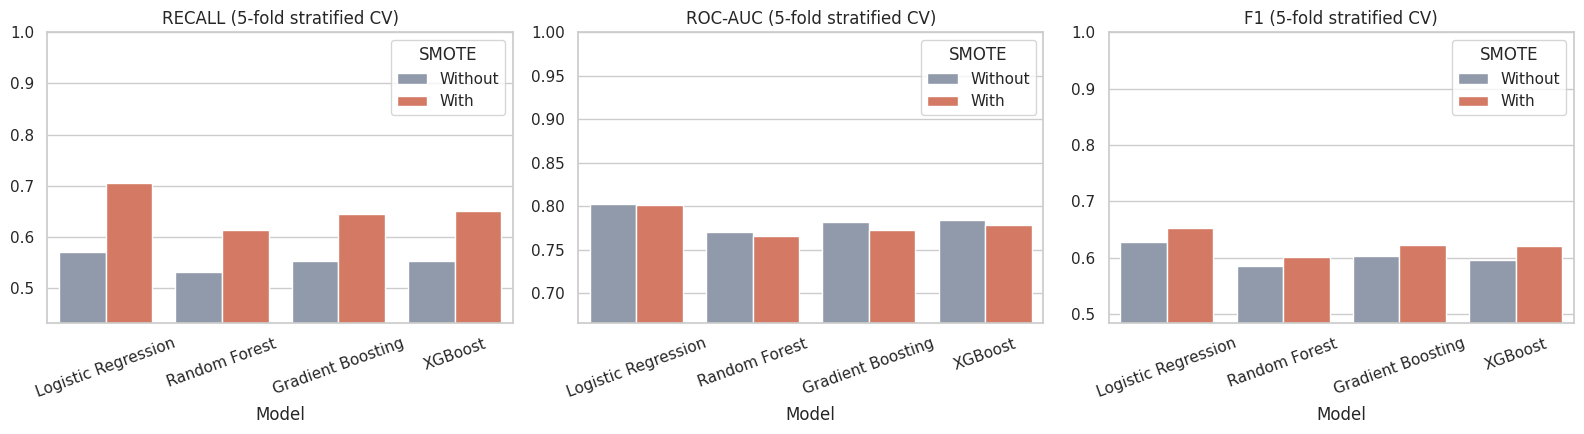

,Model,SMOTE,roc_auc_mean,recall_mean,f1_mean
0,Logistic Regression,Without,0.802,0.570,0.628
1,Logistic Regression,With,0.801,0.705,0.653
2,XGBoost,Without,0.784,0.553,0.596
3,Gradient Boosting,Without,0.782,0.553,0.603
4,XGBoost,With,0.779,0.650,0.620
5,Gradient Boosting,With,0.772,0.645,0.624
6,Random Forest,Without,0.771,0.532,0.585
7,Random Forest,With,0.766,0.613,0.601


BEST CONFIGURATION -> Logistic Regression | SMOTE: False


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m in zip(axes, ["recall","roc_auc","f1"]):
    sns.barplot(data=results, x="Model", y=m+"_mean", hue="SMOTE", palette=["#8d99ae","#e76f51"], ax=ax)
    ax.set_title(m.upper().replace("_","-")+" (5-fold stratified CV)"); ax.set_ylabel("")
    ax.set_ylim(max(0, results[m+"_mean"].min()-0.1), 1); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("fig4_cv_comparison.png", dpi=200); plt.show()

ranked = results.sort_values(["roc_auc_mean","recall_mean"], ascending=False).reset_index(drop=True)
display(ranked[["Model","SMOTE","roc_auc_mean","recall_mean","f1_mean"]].round(3))
best_name, best_smote = ranked.loc[0,"Model"], ranked.loc[0,"SMOTE"] == "With"
print("BEST CONFIGURATION ->", best_name, "| SMOTE:", best_smote)

## 5. Hold-out test of the best model (Table 5 and Figure 5)
80/20 stratified split.

TABLE 5 – Hold-out performance


,Metric,Value
0,Accuracy,0.800
1,Precision,0.774
2,Recall,0.649
3,F1-score,0.706
4,ROC-AUC,0.833


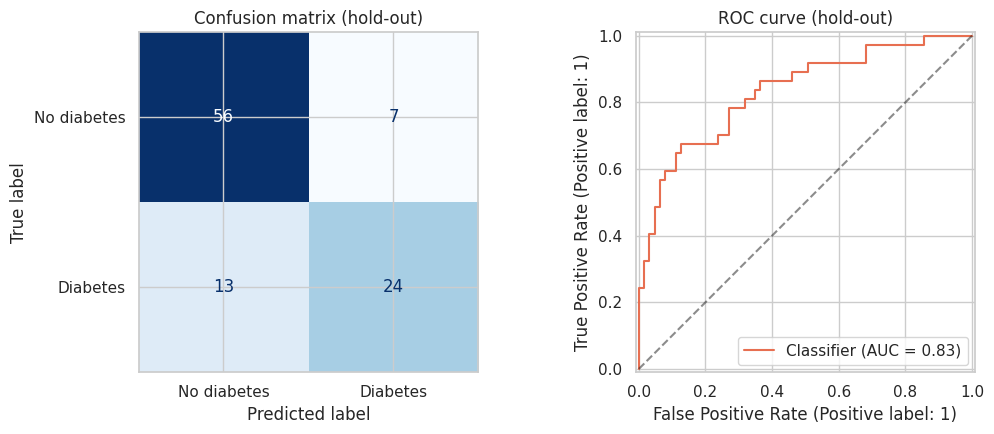

Confusion matrix [[TN, FP],[FN, TP]]:
 [[56  7]
 [13 24]]


In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
best = build(best_name, best_smote).fit(X_tr, y_tr)
pred, proba = best.predict(X_te), best.predict_proba(X_te)[:,1]

t5 = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1-score","ROC-AUC"],
    "Value":[accuracy_score(y_te,pred), precision_score(y_te,pred), recall_score(y_te,pred),
             f1_score(y_te,pred), roc_auc_score(y_te,proba)]}).round(3)
print("TABLE 5 – Hold-out performance"); display(t5)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["No diabetes","Diabetes"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (hold-out)")
RocCurveDisplay.from_predictions(y_te, proba, ax=ax[1], color="#e76f51"); ax[1].plot([0,1],[0,1],"k--",alpha=.5)
ax[1].set_title("ROC curve (hold-out)")
plt.tight_layout(); plt.savefig("fig5_holdout.png", dpi=200); plt.show()
print("Confusion matrix [[TN, FP],[FN, TP]]:\n", confusion_matrix(y_te, pred))

## 6. Subgroup check (Table 6)
Out-of-fold predictions, so every patient is scored by a model that never saw them.

In [6]:
oof = cross_val_predict(build(best_name, best_smote), X, y, cv=skf, method="predict_proba")[:,1]
ev = pd.DataFrame({"Age": data["Age"], "BMI": data["BMI"], "y": y, "proba": oof, "pred": (oof>=.5).astype(int)})
ev["Age group"] = pd.cut(ev["Age"], [0,39,59,120], labels=["Age < 40","Age 40–59","Age 60+"])
ev["BMI group"] = pd.cut(ev["BMI"], [0,24.99,29.99,100], labels=["BMI normal (<25)","BMI overweight (25–30)","BMI obese (30+)"])

out = []
for col in ["Age group","BMI group"]:
    for g, d in ev.groupby(col):
        out.append({"Subgroup": g, "n": len(d), "Diabetic %": round(d["y"].mean()*100,1),
                    "Recall": round(recall_score(d["y"], d["pred"], zero_division=0),3),
                    "Precision": round(precision_score(d["y"], d["pred"], zero_division=0),3),
                    "ROC-AUC": round(roc_auc_score(d["y"], d["proba"]),3)})
print("TABLE 6 – Out-of-fold performance by subgroup"); display(pd.DataFrame(out))

TABLE 6 – Out-of-fold performance by subgroup


,Subgroup,n,Diabetic %,Recall,Precision,ROC-AUC
0,Age < 40,139,18.7,0.346,0.600,0.822
1,Age 40–59,260,38.1,0.455,0.652,0.716
2,Age 60+,101,60.4,0.852,0.765,0.804
3,BMI normal (<25),129,16.3,0.143,0.750,0.798
4,BMI overweight (25–30),174,28.7,0.300,0.556,0.706
5,BMI obese (30+),197,58.4,0.765,0.727,0.755


## 7. Explainability: permutation importance (Figure 6) and SHAP (Figure 7)

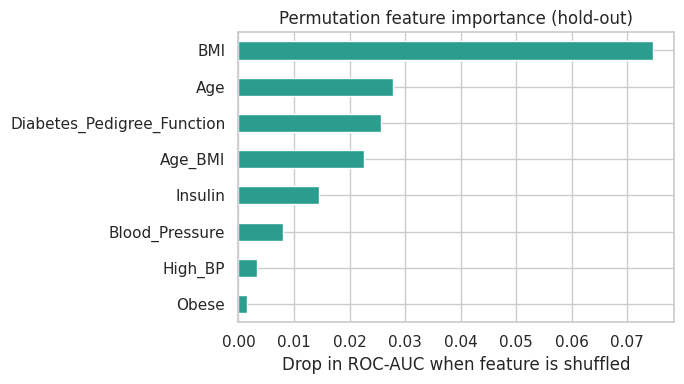

In [7]:
perm = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=20, random_state=RS)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(7,4)); imp.plot(kind="barh", color="#2a9d8f")
plt.xlabel("Drop in ROC-AUC when feature is shuffled"); plt.title("Permutation feature importance (hold-out)")
plt.tight_layout(); plt.savefig("fig6_permutation.png", dpi=200); plt.show()

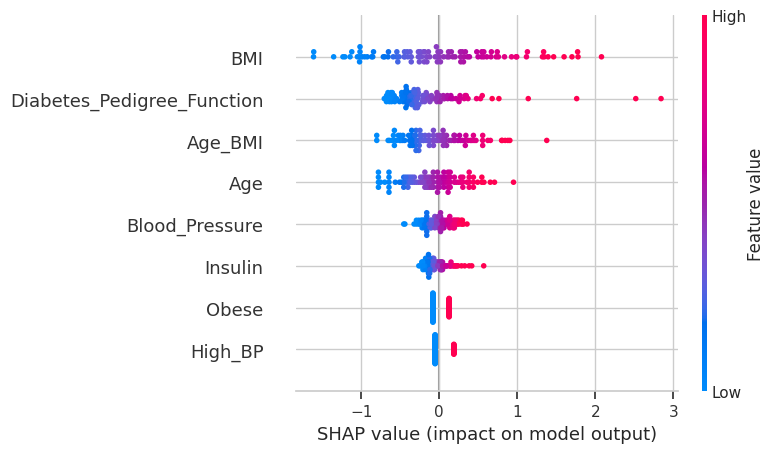

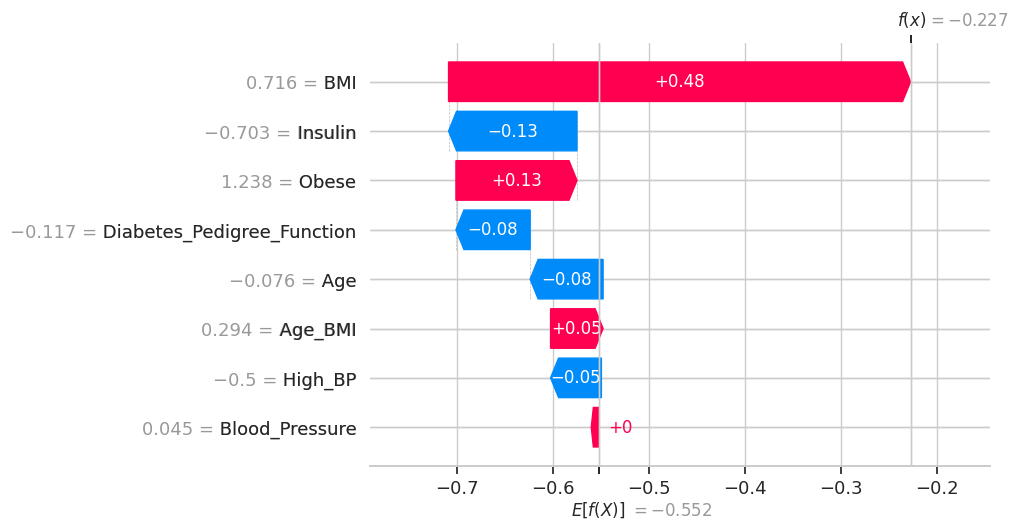

In [8]:
import shap
clf = best.named_steps["clf"]
if best_name == "Logistic Regression":
    sc = best.named_steps["scaler"]
    Xtr_t = pd.DataFrame(sc.transform(X_tr), columns=X.columns, index=X_tr.index)
    Xte_t = pd.DataFrame(sc.transform(X_te), columns=X.columns, index=X_te.index)
    sv = shap.Explainer(clf, Xtr_t)(Xte_t)
else:
    sv = shap.TreeExplainer(clf)(X_te)
    if sv.values.ndim == 3: sv = sv[:, :, 1]

shap.summary_plot(sv.values, X_te, show=False); plt.tight_layout()
plt.savefig("fig7a_shap_summary.png", dpi=200, bbox_inches="tight"); plt.show()
shap.plots.waterfall(sv[0], show=False)
plt.savefig("fig7b_shap_waterfall.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. Why k = 5? Sensitivity check on k (k = 3, 5, 10)

In [9]:
k_rows = []
for k in [3, 5, 10]:
    s = StratifiedKFold(n_splits=k, shuffle=True, random_state=RS)
    for n in ["Logistic Regression", "Random Forest"]:
        cv = cross_validate(build(n, True), X, y, cv=s, scoring={"recall":"recall","roc_auc":"roc_auc"})
        k_rows.append({"k": k, "Model": n, "Val patients/fold": len(X)//k,
                       "Recall": f"{cv['test_recall'].mean():.3f} ± {cv['test_recall'].std():.3f}",
                       "ROC-AUC": f"{cv['test_roc_auc'].mean():.3f} ± {cv['test_roc_auc'].std():.3f}"})
display(pd.DataFrame(k_rows))

,k,Model,Val patients/fold,Recall,ROC-AUC
0,3,Logistic Regression,166,0.710 ± 0.047,0.803 ± 0.015
1,3,Random Forest,166,0.624 ± 0.020,0.770 ± 0.020
2,5,Logistic Regression,100,0.705 ± 0.076,0.801 ± 0.037
3,5,Random Forest,100,0.613 ± 0.082,0.766 ± 0.044
4,10,Logistic Regression,50,0.687 ± 0.108,0.802 ± 0.049
5,10,Random Forest,50,0.628 ± 0.064,0.764 ± 0.047


## 9. Download the figures for the article

In [10]:
from google.colab import files
for f in ["fig4_cv_comparison.png","fig5_holdout.png","fig6_permutation.png","fig7a_shap_summary.png","fig7b_shap_waterfall.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>